# Heart Disease Prediction - Part 2 (Chest X-ray, Cardiomegaly)

Fine-tunes an ImageNet-pretrained **DenseNet-121** to find **cardiomegaly** (enlarged heart) on a frontal chest X-ray. This is the image half of the project, the Streamlit app shows it next to the clinical model from Part 1.

**Why chest X-ray / cardiomegaly and not MRI:**
- An enlarged heart is the heart finding that can be seen on a normal chest X-ray. It is a sign of heart failure, cardiomyopathy, valve disease or long-term high blood pressure.
- Chest X-rays are the most common imaging test and a user of the app can have one as a PNG / JPG. A cardiac MRI is a 3D + time scan (NIfTI / DICOM, many slices per heartbeat), nobody uploads that to a web app, and the public MRI datasets have 150 patients or so.
- NIH ChestX-ray14 has 112,120 X-rays from 30,805 patients, 2,776 of them labelled Cardiomegaly, which is enough to fine-tune a CNN.

**Important:** the X-ray patients are not the UCI patients, there is no dataset with both. So this model can not be "added" to the Part 1 model by training, it is a second, independent opinion. How the app combines them is explained at the end.

What is in this notebook:
1. Downloading NIH ChestX-ray14 and taking a balanced subset (all cardiomegaly images + 3 negatives for each)
2. Patient-wise split (the same patient never in train and test)
3. DenseNet-121 fine-tuning (same recipe as the intent classifier: AdamW, warmup + linear decay, fp16, gradient clipping, early stopping)
4. Evaluation: ROC AUC, recall, confusion matrix, threshold for a target recall, results for PA vs AP views
5. Grad-CAM, to see where the model looks
6. CPU latency and saving the model to Google Drive for the app

Runtime -> Change runtime type -> T4 GPU.

In [5]:
import os
import gc
import json
import time
import glob
import random
import shutil
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, recall_score, precision_score, roc_auc_score, roc_curve

In [6]:
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader
from torchvision import transforms
from tqdm.auto import tqdm

# the same versions have to be used in the streamlit app
print('torch', torch.__version__, '| torchvision', torchvision.__version__)

torch 2.11.0+cu130 | torchvision 0.26.0+cu130


In [7]:
# the model and the resized images are saved in google drive
from google.colab import drive
drive.mount('/content/drive')

save_dir = '/content/drive/MyDrive/heart_disease'
os.makedirs(save_dir, exist_ok = True)
print(os.listdir(save_dir))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[]


In [8]:
# needs a GPU runtime (Runtime -> Change runtime type -> T4 GPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('Device :', device)

Device : cuda


# Data Loading

**NIH ChestX-ray14** (Wang et al., CVPR 2017, NIH Clinical Center). Kaggle: `nih-chest-xrays/data`.

What is inside:
- `images_001/images/` ... `images_012/images/`: 112,120 PNG files, 1024 x 1024, grayscale
- `Data_Entry_2017.csv`: one row per image, `Finding Labels` (one or more of 14 findings separated by `|`, or `No Finding`), `Patient ID`, age, gender, `View Position` (PA or AP)
- `train_val_list.txt` / `test_list.txt`: the official split, done **by patient**
- The labels were mined from the radiology reports with NLP, not drawn by a radiologist for every image, so some labels are wrong (the paper estimates > 90% accuracy for most findings). The test scores are measured against these noisy labels.

The full zip is about 42 GB. Only ~11,000 images are needed, so they are read straight from the zip, resized to 256 x 256 and saved (about 0.5 GB). The resized images are copied to Drive, so the next session skips the download.

Colab disk is ~110 GB on a GPU runtime, so the zip fits. If it does not, run the notebook on Kaggle (the dataset is already attached there, set `on_kaggle = True`).

In [9]:
# True -> running in a kaggle notebook with the nih-chest-xrays/data dataset attached, False -> colab
on_kaggle = False

img_size = 256   # images are stored at this size
crop_size = 224  # and the model sees 224 x 224
img_dir = '/content/cxr256' if not on_kaggle else '/kaggle/working/cxr256'
cache_zip = save_dir + '/cxr256.zip'

In [10]:
# from the second session on, the resized images are taken from drive and nothing is downloaded
have_cache = os.path.exists(cache_zip) and os.path.exists(save_dir + '/cxr_subset.csv')
print('Cache in drive :', have_cache)

if have_cache:
    shutil.unpack_archive(cache_zip, img_dir)

Cache in drive : False


In [11]:
if not have_cache and not on_kaggle:
    !kaggle datasets download -d nih-chest-xrays/data -p /content

Dataset URL: https://www.kaggle.com/datasets/nih-chest-xrays/data
License(s): CC0-1.0
100% 42.0G/42.0G [04:50<00:00, 155MB/s]



In [12]:
if not have_cache:
    if on_kaggle:
        all_png = glob.glob('/kaggle/input/**/images_*/images/*.png', recursive = True)
        path_of = {os.path.basename(p): p for p in all_png}
        meta_path = glob.glob('/kaggle/input/**/Data_Entry_2017.csv', recursive = True)[0]
        labels = pd.read_csv(meta_path)
        test_names = set(open(os.path.join(os.path.dirname(meta_path), 'test_list.txt')).read().split())
    else:
        zf = zipfile.ZipFile('/content/data.zip', 'r')
        path_of = {os.path.basename(n): n for n in zf.namelist() if n.endswith('.png')}
        labels = pd.read_csv(zf.open('Data_Entry_2017.csv'))
        test_names = set(zf.read('test_list.txt').decode().split())
    print(len(path_of), 'images')

112120 images


In [13]:
if not have_cache:
    labels = labels[['Image Index', 'Finding Labels', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position']]
    labels.columns = ['image', 'findings', 'patient_id', 'age', 'sex', 'view']
    labels['cardiomegaly'] = labels['findings'].str.contains('Cardiomegaly').astype(int)
    labels['official_test'] = labels['image'].isin(test_names)

In [14]:
if not have_cache:
    print(labels.shape)
    print(labels['cardiomegaly'].value_counts())
    display(labels.head())

(112120, 8)
cardiomegaly
0    109344
1      2776
Name: count, dtype: int64


,image,findings,patient_id,age,sex,view,cardiomegaly,official_test
0,00000001_000.png,Cardiomegaly,1,58,M,PA,1,False
1,00000001_001.png,Cardiomegaly|Emphysema,1,58,M,PA,1,False
2,00000001_002.png,Cardiomegaly|Effusion,1,58,M,PA,1,False
3,00000002_000.png,No Finding,2,81,M,PA,0,False
4,00000003_000.png,Hernia,3,81,F,PA,0,True


## Balanced subset

Only 2.5% of the images have cardiomegaly. All of them are kept, plus 3 negatives for every positive:
- half of the negatives are `No Finding`
- half have **other** findings (effusion, nodule, ...) but no cardiomegaly

The second half matters. With only `No Finding` as negatives the model could learn "anything abnormal -> cardiomegaly". With other findings in the negatives it has to learn the heart size itself. It also matters because many cardiomegaly images also have effusion or edema (heart failure), the model must not just look for fluid.

In [15]:
neg_per_pos = 3

In [16]:
if not have_cache:
    pos = labels[labels['cardiomegaly'] == 1]
    neg_clean = labels[labels['findings'] == 'No Finding']
    neg_other = labels[(labels['cardiomegaly'] == 0) & (labels['findings'] != 'No Finding')]

    n_half = int(len(pos) * neg_per_pos / 2)
    subset = pd.concat([pos, neg_clean.sample(n_half, random_state = 42), neg_other.sample(n_half, random_state = 42)])
    subset = subset.sample(frac = 1, random_state = 42).reset_index(drop = True)
    print(subset.shape)
    print(subset['cardiomegaly'].value_counts())

(11104, 8)
cardiomegaly
0    8328
1    2776
Name: count, dtype: int64


In [17]:
def resize_and_save(name):
    out_path = os.path.join(img_dir, name)
    if os.path.exists(out_path):
        return
    if on_kaggle:
        img = Image.open(path_of[name])
    else:
        img = Image.open(zf.open(path_of[name]))
    img = img.convert('L').resize((img_size, img_size), Image.BILINEAR)
    img.save(out_path)

In [18]:
# this takes about 10 minutes, the images are read straight from the zip
if not have_cache:
    os.makedirs(img_dir, exist_ok = True)
    for name in tqdm(subset['image']):
        resize_and_save(name)

    subset.to_csv(save_dir + '/cxr_subset.csv', index = False)
    shutil.make_archive(save_dir + '/cxr256', 'zip', img_dir)
    print(len(os.listdir(img_dir)), 'images saved')

  0%|          | 0/11104 [00:00<?, ?it/s]

11104 images saved


In [19]:
# the 42 gb zip is not needed anymore
if not have_cache and not on_kaggle:
    zf.close()
    os.remove('/content/data.zip')

In [20]:
subset = pd.read_csv(save_dir + '/cxr_subset.csv')
subset.head()

,image,findings,patient_id,age,sex,view,cardiomegaly,official_test
0,00025777_001.png,Infiltration,25777,44,F,AP,0,False
1,00026810_004.png,Mass,26810,55,M,AP,0,True
2,00020623_000.png,No Finding,20623,72,M,PA,0,False
3,00022719_000.png,Cardiomegaly|Effusion,22719,58,F,PA,1,False
4,00021771_000.png,Infiltration,21771,54,M,PA,0,False


# EDA

In [21]:
subset['cardiomegaly'].value_counts()

,count
cardiomegaly,
0,8328
1,2776


In [22]:
subset['patient_id'].nunique()

6778

In [23]:
# share of cardiomegaly by view position
pd.crosstab(subset['view'], subset['cardiomegaly'], normalize = 'index').round(3)

cardiomegaly,0,1
view,,
AP,0.735,0.265
PA,0.761,0.239


**PA vs AP.** In a PA X-ray (standing, X-ray from behind) the heart is close to the film and its size is close to the real size. In an AP X-ray (often a portable X-ray in bed, for sicker patients) the heart is far from the film and looks up to ~15-20% bigger. So AP images have more cardiomegaly labels and also look bigger. The model can partly learn "AP -> cardiomegaly", which is why the results are checked separately for PA and AP at the end.

In [24]:
subset['findings'].str.split('|').explode().value_counts()

,count
findings,
No Finding,4164
Cardiomegaly,2776
Infiltration,2241
Effusion,2131
Atelectasis,1336
Nodule,641
Mass,585
Consolidation,540
Pneumothorax,460


In [25]:
# other findings that come with cardiomegaly
subset[subset['cardiomegaly'] == 1]['findings'].str.split('|').explode().value_counts().head(8)

,count
findings,
Cardiomegaly,2776
Effusion,1063
Infiltration,587
Atelectasis,370
Consolidation,169
Edema,127
Pleural_Thickening,111
Nodule,108


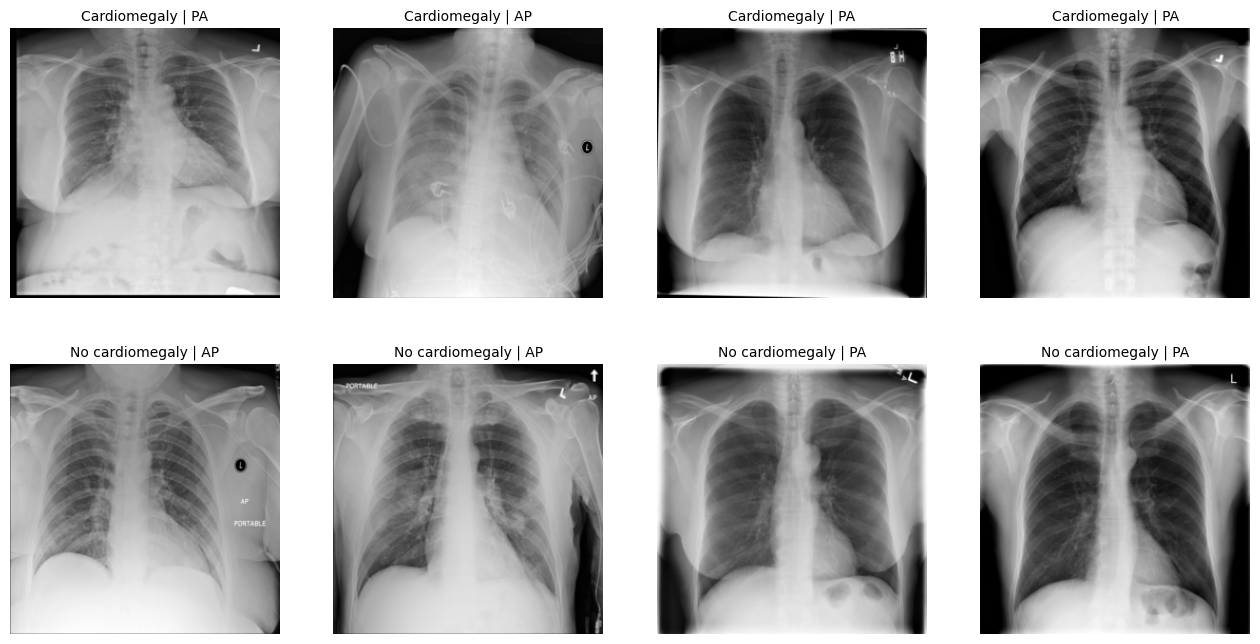

In [26]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16,8))
samples = pd.concat([subset[subset['cardiomegaly'] == 1].head(4), subset[subset['cardiomegaly'] == 0].head(4)])
for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):
    ax.imshow(Image.open(os.path.join(img_dir, row['image'])), cmap = 'gray')
    ax.set_title(('Cardiomegaly' if row['cardiomegaly'] == 1 else 'No cardiomegaly') + ' | ' + row['view'], fontsize = 10)
    ax.axis('off')
plt.show()

What the model has to learn is the **cardiothoracic ratio**: width of the heart / width of the chest. Above 0.5 on a PA X-ray is called cardiomegaly.

# Train / Validation / Test split

The official NIH test list is used as the test set. It is split by patient, and many patients have 10+ X-rays, so a random split would put the same patient (and the same heart) in train and test and the score would be too high.

The validation set is also split by patient (`GroupShuffleSplit` on `patient_id`), 10% of the training patients.

In [27]:
test_df = subset[subset['official_test'] == True].reset_index(drop = True)
trainval = subset[subset['official_test'] == False].reset_index(drop = True)

gss = GroupShuffleSplit(n_splits = 1, test_size = 0.1, random_state = 42)
train_idx, val_idx = next(gss.split(trainval, groups = trainval['patient_id']))
train_df = trainval.iloc[train_idx].reset_index(drop = True)
val_df = trainval.iloc[val_idx].reset_index(drop = True)

train_df.shape, val_df.shape, test_df.shape

((7310, 8), (793, 8), (3001, 8))

In [28]:
# no patient is in two sets
print(len(set(train_df['patient_id']) & set(val_df['patient_id'])), len(set(train_df['patient_id']) & set(test_df['patient_id'])))

0 0


In [29]:
pd.DataFrame({'train': train_df['cardiomegaly'].mean(), 'val': val_df['cardiomegaly'].mean(), 'test': test_df['cardiomegaly'].mean()}, index = ['cardiomegaly share']).round(3)

,train,val,test
cardiomegaly share,0.207,0.242,0.356


# DenseNet-121 Fine-tuning

DenseNet-121 pretrained on ImageNet, the same backbone as CheXNet (Rajpurkar et al., 2017). The last layer (1000 ImageNet classes) is replaced by one output, the logit of cardiomegaly.

Augmentation, only small changes a real X-ray can have:
- small random crop (zoom) and rotation (patient not perfectly straight)
- small brightness / contrast change (different machines)
- **no horizontal flip.** The heart is on the left side of the chest. A flipped X-ray is a different (rare) condition, dextrocardia, and it changes where the heart border is. Flipping is a normal augmentation for photos, not for chest X-rays.

The X-ray is grayscale, it is copied to 3 channels because the pretrained network expects RGB, and normalized with the ImageNet mean / std.

In [30]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

In [31]:
batch_size = 32
epochs = 8
lr = 1e-4
weight_decay = 1e-4
warmup_ratio = 0.1
patience = 2
num_workers = 2

In [32]:
# True -> runs everything on a small sample just to check that the pipeline works, False -> full training
debug = False

In [33]:
if debug == True:
    train_df = train_df.iloc[:256].copy()
    val_df = val_df.iloc[:128].copy()
    test_df = test_df.iloc[:128].copy()
    epochs = 1

In [34]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels = 3),
    transforms.RandomResizedCrop(crop_size, scale = (0.85, 1.0), ratio = (0.95, 1.05)),
    transforms.RandomRotation(7),
    transforms.ColorJitter(brightness = 0.1, contrast = 0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# validation / test / app: no randomness, just resize and center crop
eval_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels = 3),
    transforms.Resize(img_size),
    transforms.CenterCrop(crop_size),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

In [35]:
class CXRDataset(torch.utils.data.Dataset):
    def __init__(self, df, transform):
        self.names = df['image'].values
        self.labels = df['cardiomegaly'].values
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = Image.open(os.path.join(img_dir, self.names[idx])).convert('L')
        return self.transform(img), torch.tensor(self.labels[idx], dtype = torch.float32)

In [36]:
train_ds = CXRDataset(train_df, train_tf)
val_ds = CXRDataset(val_df, eval_tf)
test_ds = CXRDataset(test_df, eval_tf)

train_loader = DataLoader(train_ds, batch_size = batch_size, shuffle = True, num_workers = num_workers, pin_memory = True)
val_loader = DataLoader(val_ds, batch_size = 64, shuffle = False, num_workers = num_workers, pin_memory = True)
test_loader = DataLoader(test_ds, batch_size = 64, shuffle = False, num_workers = num_workers, pin_memory = True)

In [37]:
images, targets = next(iter(train_loader))
images.shape, targets[:8]

(torch.Size([32, 3, 224, 224]), tensor([1., 0., 0., 0., 0., 0., 0., 0.]))

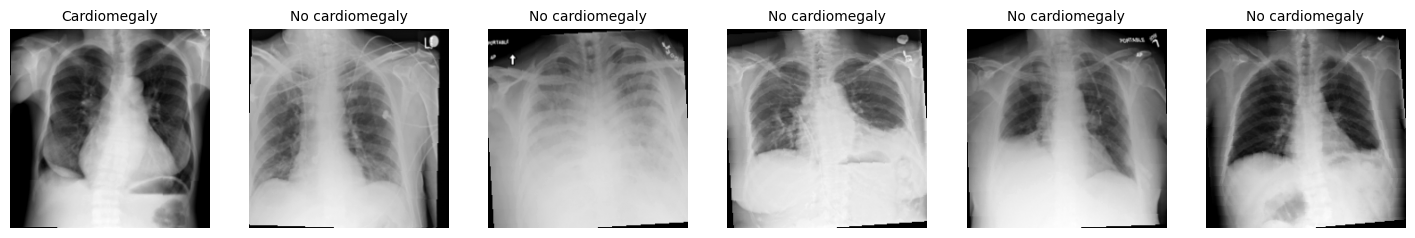

In [38]:
# what the model sees after augmentation (un-normalized for plotting)
fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(18,4))
for i, ax in enumerate(axes):
    img = images[i, 0] * std[0] + mean[0]
    ax.imshow(img, cmap = 'gray')
    ax.set_title('Cardiomegaly' if targets[i] == 1 else 'No cardiomegaly', fontsize = 10)
    ax.axis('off')
plt.show()

## Model

In [39]:
def make_model(pretrained = True):
    weights = torchvision.models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
    model = torchvision.models.densenet121(weights = weights)
    model.classifier = nn.Linear(model.classifier.in_features, 1)
    return model

cnn_model = make_model()
cnn_model.to(device)
sum(p.numel() for p in cnn_model.parameters())

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 172MB/s]


6954881

In [40]:
# there are 3 negatives for each positive, pos_weight = 3 gives both classes the same total weight in the loss
pos_weight = torch.tensor([(train_df['cardiomegaly'] == 0).sum() / (train_df['cardiomegaly'] == 1).sum()], device = device)
criterion = nn.BCEWithLogitsLoss(pos_weight = pos_weight)
print('pos_weight :', round(pos_weight.item(), 3))

pos_weight : 3.825


In [41]:
# no weight decay on bias and batch norm weights
decay, no_decay = [], []
for n, p in cnn_model.named_parameters():
    if p.ndim == 1:
        no_decay.append(p)
    else:
        decay.append(p)
optimizer = torch.optim.AdamW([{'params': decay, 'weight_decay': weight_decay}, {'params': no_decay, 'weight_decay': 0.0}], lr = lr)

In [42]:
# learning rate goes up for the first 10% of the steps and then decays linearly to 0
total_steps = len(train_loader) * epochs
warmup_steps = int(warmup_ratio * total_steps)

def lr_lambda(step):
    if step < warmup_steps:
        return step / max(1, warmup_steps)
    return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

# mixed precision (fp16) to make training faster on the gpu
scaler = torch.amp.GradScaler('cuda', enabled = use_amp)

print('Total steps :', total_steps, '| Warmup steps :', warmup_steps)

Total steps : 1832 | Warmup steps : 183


In [43]:
def train_one_epoch(model, loader):
    model.train()
    total_loss = 0
    n = 0
    for images, targets in tqdm(loader, leave = False):
        images, targets = images.to(device), targets.to(device)
        optimizer.zero_grad()
        with torch.autocast(device_type = device.type, dtype = torch.float16, enabled = use_amp):
            logits = model(images).squeeze(1)
            loss = criterion(logits, targets)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total_loss += loss.item() * targets.size(0)
        n += targets.size(0)
    return total_loss / n

In [44]:
def evaluate(model, loader):
    model.eval()
    total_loss = 0
    all_probs = []
    all_labels = []
    with torch.no_grad():
        for images, targets in loader:
            images, targets = images.to(device), targets.to(device)
            with torch.autocast(device_type = device.type, dtype = torch.float16, enabled = use_amp):
                logits = model(images).squeeze(1)
            total_loss += criterion(logits.float(), targets).item() * targets.size(0)
            all_probs.append(torch.sigmoid(logits.float()).cpu().numpy())
            all_labels.extend(targets.cpu().numpy())
    probs = np.concatenate(all_probs)
    labels = np.array(all_labels).astype(int)
    auc = roc_auc_score(labels, probs) if len(np.unique(labels)) == 2 else np.nan
    return total_loss / len(labels), auc, probs, labels

## Training

The best epoch is chosen by **validation ROC AUC** and not accuracy. AUC does not depend on the threshold, and the threshold is chosen later for recall.

In [59]:
best_auc = -1
best_state = None
bad_epochs = 0
history = {'train_loss': [], 'val_loss': [], 'val_auc': []}

for epoch in range(epochs):
    train_loss = train_one_epoch(cnn_model, train_loader)
    val_loss, val_auc, _, _ = evaluate(cnn_model, val_loader)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_auc'].append(val_auc)
    print(f'Epoch {epoch + 1}/{epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val auc {val_auc:.4f}')

    # keep the weights of the best epoch, stop if it doesn't improve for 'patience' epochs
    if val_auc > best_auc:
        best_auc = val_auc
        best_state = {k: v.detach().cpu().clone() for k, v in cnn_model.state_dict().items()}
        bad_epochs = 0
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print('Early stopping')
            break

cnn_model.load_state_dict(best_state)
print('Best validation AUC :', best_auc)

  0%|          | 0/229 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dc817467560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7dc817467560>self._shutdown_workers()
Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        self._shutdown_workers()
if w.is_alive():
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        if w.is_alive():
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/lib/python3.13/multiprocessing/process.py", line 16

Epoch 1/8 | train loss 0.4208 | val loss 0.5874 | val auc 0.9293


  0%|          | 0/229 [00:00<?, ?it/s]

Epoch 2/8 | train loss 0.3344 | val loss 0.6727 | val auc 0.9266


  0%|          | 0/229 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dc817467560>
Exception ignored in: Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7dc817467560>    self._shutdown_workers()

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    if w.is_alive():    
self._shutdown_workers()  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
assert self._parent_pid == os.getpid(), 'can only test a child process'    if w.is_alive():
AssertionError
  File "/usr/lib/python3.13/multiprocessing/proce

Epoch 3/8 | train loss 0.2762 | val loss 0.7124 | val auc 0.9245
Early stopping
Best validation AUC : 0.9292585274542431


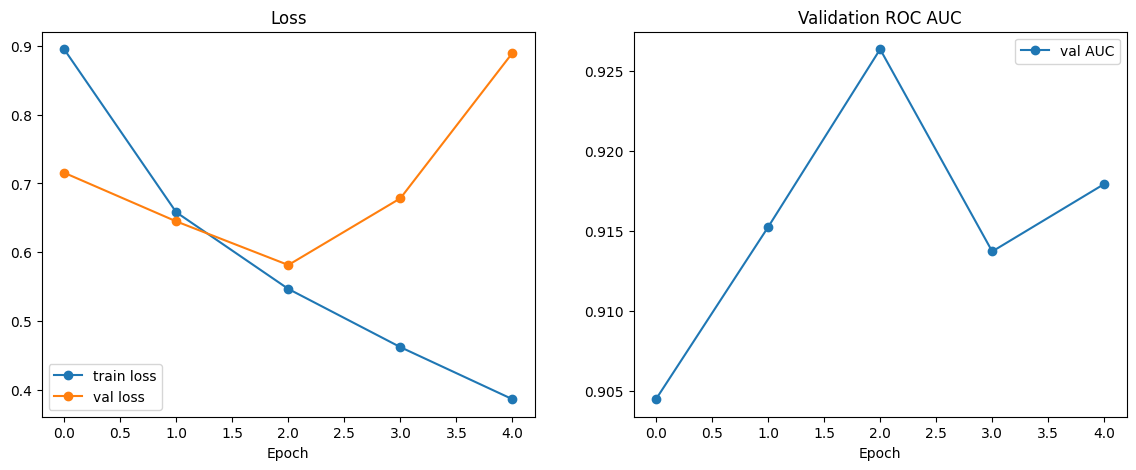

In [46]:
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (14,5))
axes[0].plot(history['train_loss'], marker = 'o', label = 'train loss')
axes[0].plot(history['val_loss'], marker = 'o', label = 'val loss')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history['val_auc'], marker = 'o', label = 'val AUC')
axes[1].set_title('Validation ROC AUC')
axes[1].set_xlabel('Epoch')
axes[1].legend()
plt.show()

# Threshold

`pos_weight` changes what the probabilities mean, so 0.5 is not a natural cut. The threshold is chosen on the **validation** set (not the test set) as the highest one that still finds `target_recall` of the cardiomegaly images.

In [47]:
target_recall = 0.90

In [48]:
_, _, val_probs, val_labels = evaluate(cnn_model, val_loader)

rows = []
for t in np.arange(0.05, 0.96, 0.05):
    pred = (val_probs >= t).astype(int)
    rows.append({'threshold': round(t, 2), 'recall': recall_score(val_labels, pred, zero_division = 0),
                 'precision': precision_score(val_labels, pred, zero_division = 0), 'accuracy': accuracy_score(val_labels, pred)})
thr_table = pd.DataFrame(rows)
thr_table.round(4)

,threshold,recall,precision,accuracy
0,0.05,0.9896,0.3545,0.5612
1,0.10,0.9844,0.4004,0.6393
2,0.15,0.9792,0.4352,0.6873
3,0.20,0.9740,0.4550,0.7112
4,0.25,0.9583,0.4868,0.7453
5,0.30,0.9427,0.5070,0.7642
6,0.35,0.9323,0.5296,0.7831
7,0.40,0.9271,0.5494,0.7982
8,0.45,0.9167,0.5733,0.8146
9,0.50,0.8906,0.5938,0.8260


In [49]:
ok = thr_table[thr_table['recall'] >= target_recall]
threshold = float(ok['threshold'].max()) if len(ok) > 0 else 0.5
print('Chosen threshold :', threshold)

Chosen threshold : 0.45


# Evaluation on the test set

ROC AUC : 0.8800718827409763
Accuracy Score : 0.7707430856381207
Recall (cardiomegaly) : 0.8250701590271281
Precision (cardiomegaly) : 0.6377440347071583


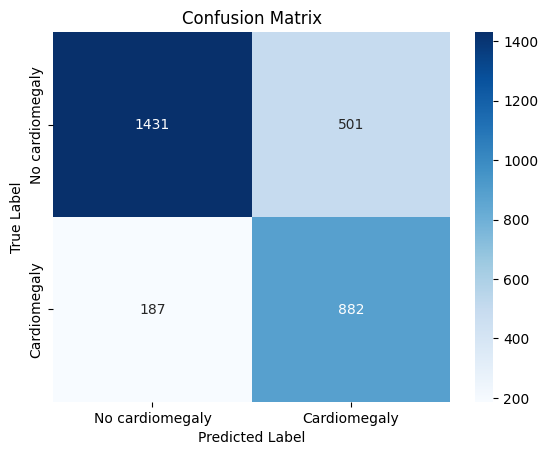

                 precision    recall  f1-score   support

No cardiomegaly    0.88443   0.74068   0.80620      1932
   Cardiomegaly    0.63774   0.82507   0.71941      1069

       accuracy                        0.77074      3001
      macro avg    0.76108   0.78288   0.76280      3001
   weighted avg    0.79655   0.77074   0.77528      3001



In [50]:
test_loss, test_auc, y_prob_cnn, y_test = evaluate(cnn_model, test_loader)
y_pred_cnn = (y_prob_cnn >= threshold).astype(int)

print('ROC AUC :', test_auc)
print('Accuracy Score :', accuracy_score(y_test, y_pred_cnn))
print('Recall (cardiomegaly) :', recall_score(y_test, y_pred_cnn))
print('Precision (cardiomegaly) :', precision_score(y_test, y_pred_cnn))

cm = confusion_matrix(y_test, y_pred_cnn)
target_names = ['No cardiomegaly', 'Cardiomegaly']
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print(classification_report(y_test, y_pred_cnn, target_names=target_names, digits=5))

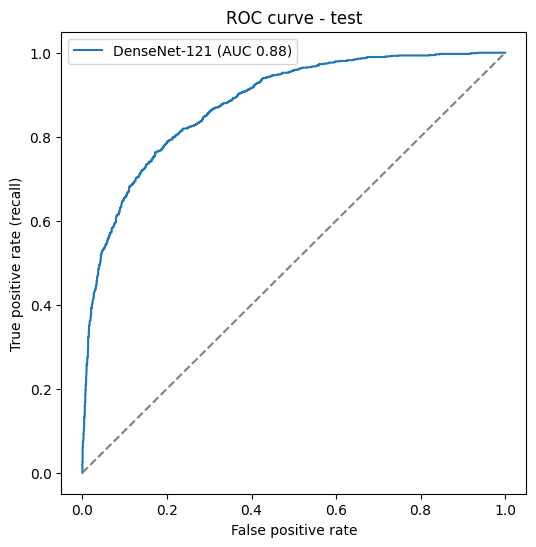

In [51]:
fpr, tpr, _ = roc_curve(y_test, y_prob_cnn)
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label = 'DenseNet-121 (AUC ' + str(round(test_auc, 3)) + ')')
plt.plot([0, 1], [0, 1], linestyle = '--', color = 'grey')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate (recall)')
plt.title('ROC curve - test')
plt.legend()
plt.show()

For reference, CheXNet reported about 0.92 AUC for cardiomegaly on NIH, and most papers are 0.87 - 0.93. Note those are on the full imbalanced test set, here the test set is the balanced subset, AUC does not change much with the balance but precision does (in a real hospital only ~2-3% of X-rays have cardiomegaly, so precision would be much lower than here).

In [52]:
# PA vs AP, and the other findings in the negatives
test_df['prob'] = y_prob_cnn
test_df['pred'] = y_pred_cnn

rows = []
for view in ['PA', 'AP']:
    part = test_df[test_df['view'] == view]
    if part['cardiomegaly'].nunique() == 2:
        rows.append({'view': view, 'images': len(part), 'cardiomegaly share': part['cardiomegaly'].mean(),
                     'roc_auc': roc_auc_score(part['cardiomegaly'], part['prob']), 'recall': recall_score(part['cardiomegaly'], part['pred'])})
pd.DataFrame(rows).round(3)

,view,images,cardiomegaly share,roc_auc,recall
0,PA,1254,0.341,0.925,0.904
1,AP,1747,0.367,0.846,0.773


In [53]:
# false positive rate for 'No Finding' negatives vs negatives with another finding
neg = test_df[test_df['cardiomegaly'] == 0].copy()
neg['group'] = np.where(neg['findings'] == 'No Finding', 'No Finding', 'Other finding')
neg.groupby('group')['pred'].mean().round(3).rename('false positive rate')

,false positive rate
group,
No Finding,0.255
Other finding,0.262


If the PA AUC is much lower than the AP AUC, or the false positive rate for "Other finding" is much higher, the model is partly using shortcuts (view, fluid, lines and tubes) and not only the heart size. That is a normal result for NIH and a good point to talk about.

# Grad-CAM

Grad-CAM shows which part of the image pushed the prediction up. It takes the last feature maps of DenseNet (7 x 7 x 1024), weights every map by the mean gradient of the output, and upsamples the result to the image size. For cardiomegaly the heat should be on the heart border, not on text markers or tubes.

The app uses the same function.

In [54]:
def grad_cam(model, x):
    model.eval()
    store = {}

    def fwd_hook(module, inp, out):
        store['act'] = out
        out.register_hook(lambda g: store.update(grad = g))

    h = model.features.register_forward_hook(fwd_hook)
    logit = model(x).squeeze()
    model.zero_grad()
    logit.backward()
    h.remove()

    weights = store['grad'].mean(dim = (2, 3), keepdim = True)
    cam = torch.relu((weights * store['act']).sum(dim = 1)).squeeze(0)
    cam = cam / (cam.max() + 1e-8)
    cam = torch.nn.functional.interpolate(cam[None, None], size = x.shape[-2:], mode = 'bilinear', align_corners = False)[0, 0]
    return torch.sigmoid(logit).item(), cam.detach().cpu().numpy()

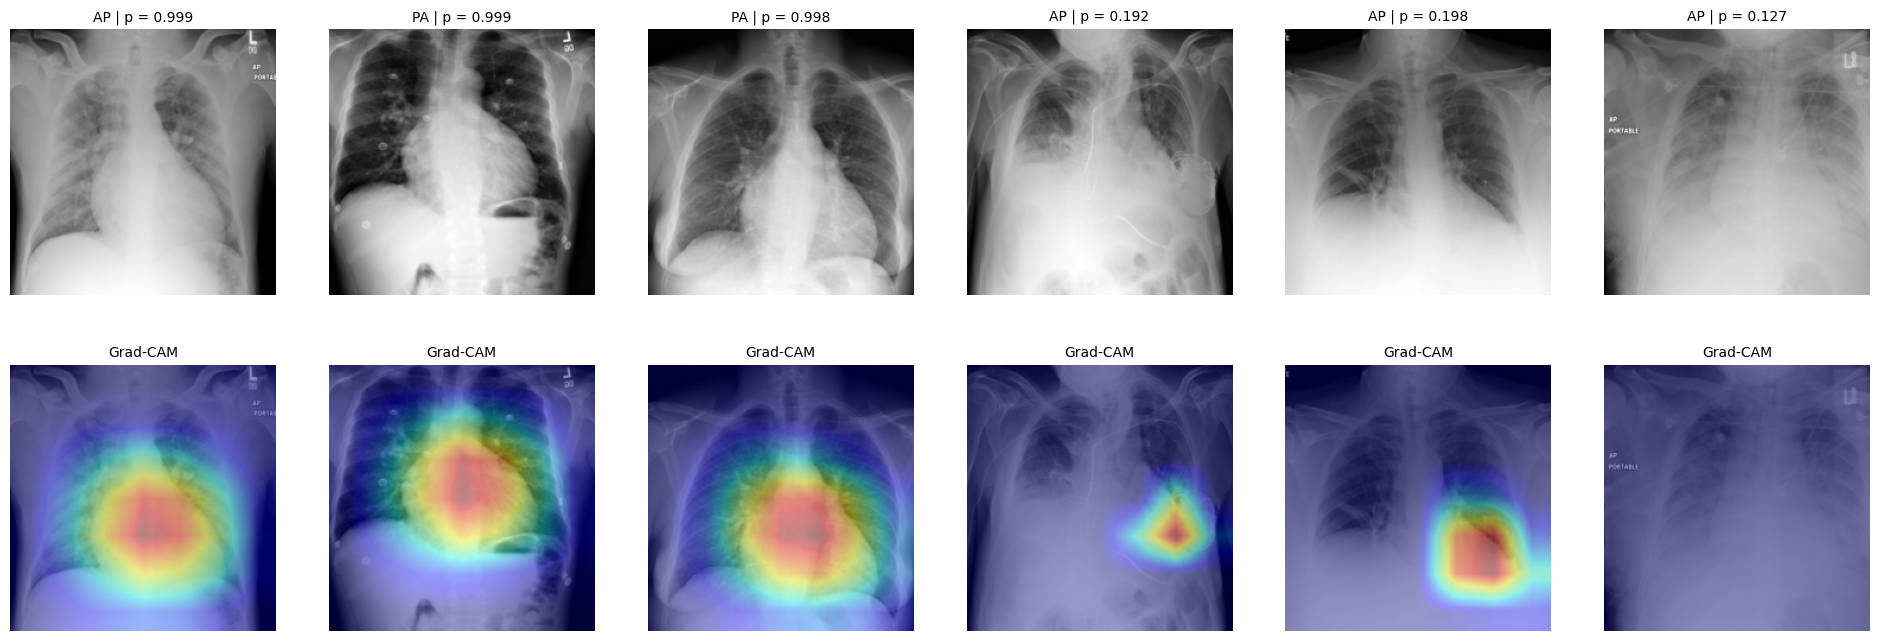

In [55]:
# the most confident cardiomegaly predictions and the missed ones
show = pd.concat([test_df[test_df['cardiomegaly'] == 1].sort_values('prob', ascending = False).head(3),
                  test_df[(test_df['cardiomegaly'] == 1) & (test_df['pred'] == 0)].head(3)])

fig, axes = plt.subplots(nrows=2, ncols=len(show), figsize=(4 * len(show), 8))
for i, (_, row) in enumerate(show.iterrows()):
    img = Image.open(os.path.join(img_dir, row['image'])).convert('L')
    x = eval_tf(img).unsqueeze(0).to(device)
    prob, cam = grad_cam(cnn_model, x)
    shown = np.array(img.resize((img_size, img_size)))[16:16 + crop_size, 16:16 + crop_size]
    axes[0, i].imshow(shown, cmap = 'gray')
    axes[0, i].set_title(row['view'] + ' | p = ' + str(round(prob, 3)), fontsize = 10)
    axes[1, i].imshow(shown, cmap = 'gray')
    axes[1, i].imshow(cam, cmap = 'jet', alpha = 0.4)
    axes[1, i].set_title('Grad-CAM', fontsize = 10)
    axes[0, i].axis('off')
    axes[1, i].axis('off')
plt.show()

# Latency on CPU

The Streamlit app runs on a CPU machine (Streamlit Community Cloud is CPU only), so one prediction is timed on the CPU.

In [56]:
cpu_model = make_model(pretrained = False)
cpu_model.load_state_dict({k: v.cpu().float() for k, v in cnn_model.state_dict().items()})
cpu_model.eval()

def predict_cpu(img):
    x = eval_tf(img).unsqueeze(0)
    with torch.inference_mode():
        return torch.sigmoid(cpu_model(x)).item()

sample_img = Image.open(os.path.join(img_dir, test_df['image'].iloc[0])).convert('L')
predict_cpu(sample_img)  # warm up

0.33379146456718445

In [57]:
times = []
for name in test_df['image'].iloc[:30]:
    img = Image.open(os.path.join(img_dir, name)).convert('L')
    start = time.perf_counter()
    predict_cpu(img)
    times.append((time.perf_counter() - start) * 1000)

print('Mean latency (ms) :', round(np.mean(times), 1))
print('p95 latency (ms) :', round(np.percentile(times, 95), 1))

Mean latency (ms) : 126.6
p95 latency (ms) : 152.5


# Save the model

In [58]:
torch.save({k: v.cpu().float() for k, v in cnn_model.state_dict().items()}, save_dir + '/cxr_model.pt')

# the app reads this file: preprocessing, threshold and the scores
cxr_config = {
    'arch': 'densenet121',
    'task': 'cardiomegaly vs no cardiomegaly, frontal chest x-ray',
    'img_size': img_size,
    'crop_size': crop_size,
    'mean': mean,
    'std': std,
    'threshold': threshold,
    'target_recall': target_recall,
    'test_metrics': {
        'roc_auc': float(test_auc),
        'accuracy': float(accuracy_score(y_test, y_pred_cnn)),
        'recall': float(recall_score(y_test, y_pred_cnn)),
        'precision': float(precision_score(y_test, y_pred_cnn)),
        'f1': float(f1_score(y_test, y_pred_cnn))
    },
    'n_train': int(len(train_df)),
    'n_test': int(len(test_df)),
    'cpu_latency_ms_mean': float(np.mean(times)),
    'torch': torch.__version__,
    'torchvision': torchvision.__version__
}
json.dump(cxr_config, open(save_dir + '/cxr_config.json', 'w'), indent = 2)
os.listdir(save_dir)

['cxr_subset.csv', 'cxr256.zip', 'cxr_model.pt', 'cxr_config.json']

# Reading the results

The numbers above raise four questions, answered in the cells below. Every section has a heading, the code, the printed numbers copied into the code cell as comments, and a **Result** cell that says what the numbers mean.

1. The threshold was picked for 90% recall on validation, but the test recall is 0.825. Why?
2. How much can the test AUC move by chance? (confidence interval, resampling **patients**, not images)
3. What would the precision be in a real hospital, where only ~2.5% of X-rays have cardiomegaly?
4. What do the mistakes look like? Is it the model or the labels?

Plus: do per-view thresholds help, and does test-time augmentation help?

## 1. Why is the test recall lower than the validation recall?

In [60]:
# view mix and cardiomegaly share in every split
mix = pd.DataFrame({
    'train': train_df['view'].value_counts(normalize = True),
    'val': val_df['view'].value_counts(normalize = True),
    'test': test_df['view'].value_counts(normalize = True)
}).round(3)
mix.loc['cardiomegaly share'] = [train_df['cardiomegaly'].mean(), val_df['cardiomegaly'].mean(), test_df['cardiomegaly'].mean()]
mix.round(3)

# ---- Output of this cell (copied from the run) ----
#                     train    val   test
# view
# AP                  0.351  0.330  0.582
# PA                  0.649  0.670  0.418
# cardiomegaly share  0.207  0.242  0.356

,train,val,test
view,,,
AP,0.351,0.330,0.582
PA,0.649,0.670,0.418
cardiomegaly share,0.207,0.242,0.356


In [61]:
# the same per-view table on validation and test, at the same threshold
val_df = val_df.copy()
val_df['prob'] = val_probs

def view_table(df_, thr):
    rows = []
    for view in ['PA', 'AP']:
        part = df_[df_['view'] == view]
        y_true = part['cardiomegaly'].values
        pred = (part['prob'].values >= thr).astype(int)
        neg = (y_true == 0).sum()
        rows.append({'view': view, 'images': len(part), 'positives': int(y_true.sum()),
                     'roc_auc': roc_auc_score(y_true, part['prob']) if len(np.unique(y_true)) == 2 else np.nan,
                     'recall': recall_score(y_true, pred, zero_division = 0),
                     'false positive rate': ((pred == 1) & (y_true == 0)).sum() / max(neg, 1)})
    return pd.DataFrame(rows).set_index('view').round(3)

print('Validation, threshold', threshold)
display(view_table(val_df, threshold))
print('Test, threshold', threshold)
display(view_table(test_df, threshold))

# ---- Output of this cell (copied from the run) ----
# Validation, threshold 0.45
#       images  positives  roc_auc  recall  false positive rate
# view
# PA       531        121    0.946   0.967                0.224
# AP       262         71    0.895   0.831                0.204
# Test, threshold 0.45
#       images  positives  roc_auc  recall  false positive rate
# view
# PA      1254        427    0.925   0.904                0.244
# AP      1747        642    0.846   0.773                0.271

Validation, threshold 0.45


,images,positives,roc_auc,recall,false positive rate
view,,,,,
PA,531,121,0.946,0.967,0.224
AP,262,71,0.895,0.831,0.204


Test, threshold 0.45


,images,positives,roc_auc,recall,false positive rate
view,,,,,
PA,1254,427,0.925,0.904,0.244
AP,1747,642,0.846,0.773,0.271


**Result 1 - the test set is a different mix, but that is only a third of the drop**

| | train | val | test |
|---|---|---|---|
| AP share of images | 35% | 33% | **58%** |
| cardiomegaly share | 21% | 24% | 36% |

| at threshold 0.45 | val PA | val AP | test PA | test AP |
|---|---|---|---|---|
| ROC AUC | 0.946 | 0.895 | 0.925 | 0.846 |
| recall | 0.967 | 0.831 | 0.904 | 0.773 |
| false positive rate | 0.224 | 0.204 | 0.244 | 0.271 |

Splitting the drop from 0.917 (val recall) to 0.825 (test recall), which is 9.2 points:
- **-3.0 points from the view mix.** 60% of the test positives are AP films against 37% of the validation positives, and AP is harder.
- **-6.1 points from recall falling inside each view** (PA 0.967 -> 0.904, AP 0.831 -> 0.773).

So the mix is a minor part. Most of the drop is that validation was optimistic: the best epoch and the threshold were both chosen on it, and it is small (71 AP positives means about +-9 points of noise on the AP recall, 121 PA positives about +-3). Test AUC drops inside each view too (PA -0.02, AP -0.05).

Correction to what I said before: the view mix explains about a third of the gap, not most of it.

AP is harder than PA on both splits (AUC gap 0.05 on validation, 0.08 on test): the heart is magnified on AP films and the border is often hidden. It is not a shortcut, because cardiomegaly is about equally common in both views (so the view tells the model nothing).

## 2. Confidence interval (resampling patients)

In [62]:
# the same patient has several X-rays, so patients (not images) are resampled
rng = np.random.default_rng(42)
groups = test_df.groupby('patient_id').indices
patients = np.array(list(groups.keys()))
y_all = test_df['cardiomegaly'].values
p_all = test_df['prob'].values

boot = []
for _ in range(500):
    chosen = rng.choice(patients, len(patients), replace = True)
    idx = np.concatenate([groups[p] for p in chosen])
    yb, pb = y_all[idx], p_all[idx]
    if len(np.unique(yb)) < 2:
        continue
    pred = (pb >= threshold).astype(int)
    boot.append({'roc_auc': roc_auc_score(yb, pb), 'recall': recall_score(yb, pred),
                 'false positive rate': ((pred == 1) & (yb == 0)).sum() / (yb == 0).sum()})
boot = pd.DataFrame(boot)
ci = boot.quantile([0.025, 0.5, 0.975]).round(3)
ci

# ---- Output of this cell (copied from the run) ----
#        roc_auc  recall  false positive rate
# 0.025    0.858   0.779                0.235
# 0.500    0.879   0.824                0.259
# 0.975    0.898   0.862                0.284

,roc_auc,recall,false positive rate
0.025,0.858,0.779,0.235
0.500,0.879,0.824,0.259
0.975,0.898,0.862,0.284


**Result 2 - the recall shortfall is real, not chance**

| | 2.5% | median | 97.5% |
|---|---|---|---|
| ROC AUC | 0.858 | 0.879 | 0.898 |
| recall at 0.45 | 0.779 | 0.824 | 0.862 |
| false positive rate | 0.235 | 0.259 | 0.284 |

- The 90% recall target is **above the whole recall interval** (the top is 0.862), so missing it is not bad luck on this test set.
- For the resume: ROC AUC 0.88 (95% CI 0.86 - 0.90).
- The interval is about 4 points wide on AUC, so differences of a few thousandths between versions of the model (like the TTA gain in section 6) are not distinguishable from noise.

## 3. Precision in a real hospital (prevalence)

In [63]:
# precision (PPV) from recall and false positive rate at any prevalence p:
# PPV = recall * p / (recall * p + fpr * (1 - p))
test_pred = (test_df['prob'].values >= threshold).astype(int)
rec = recall_score(y_all, test_pred)
fpr_all = ((test_pred == 1) & (y_all == 0)).sum() / (y_all == 0).sum()

def ppv(recall_, fpr_, p):
    return recall_ * p / (recall_ * p + fpr_ * (1 - p))

full_prevalence = 2776 / 112120   # share of cardiomegaly in the full NIH data
rows = []
for name, p in [('full NIH data', full_prevalence), ('5%', 0.05), ('10%', 0.10), ('this test set', y_all.mean())]:
    v = ppv(rec, fpr_all, p)
    rows.append({'prevalence': name, 'p': round(p, 3), 'precision': round(v, 3), 'false alarms per true find': round((1 - v) / v, 1)})
pd.DataFrame(rows)

# ---- Output of this cell (copied from the run) ----
#       prevalence      p  precision  false alarms per true find
# 0  full NIH data  0.025      0.075                        12.4
# 1             5%  0.050      0.143                         6.0
# 2            10%  0.100      0.261                         2.8
# 3  this test set  0.356      0.638                         0.6

,prevalence,p,precision,false alarms per true find
0,full NIH data,0.025,0.075,12.4
1,5%,0.050,0.143,6.0
2,10%,0.100,0.261,2.8
3,this test set,0.356,0.638,0.6


**Result 3 - at real-world prevalence most flags would be false alarms**

| prevalence of cardiomegaly | precision | false alarms per true find |
|---|---|---|
| 2.5% (full NIH data) | **0.075** | **12.4** |
| 5% | 0.143 | 6.0 |
| 10% | 0.261 | 2.8 |
| 35.6% (this test set) | 0.638 | 0.6 |

The 0.64 precision in the test set is high only because the test set has 36% positives (the subset keeps all positives and only 3 negatives for each). With the same recall (0.825) and false positive rate (0.259) at 2.5% prevalence the model gives about 12 false alarms for every true cardiomegaly found.

The formula assumes the recall and false positive rate stay the same when the mix changes. The false positive rate was about the same on "No Finding" images (0.255) and on images with other findings (0.262), so the assumption is reasonable here, but it is still an estimate and not a measurement on a real screening population.

What this means: this is a first-pass triage score and not a diagnosis, and the app text should say so. It is also why a PR curve, not only ROC, matters for rare findings.

## 4. Per-view thresholds

In [64]:
# the view (PA / AP) is known when the X-ray is taken, so a separate threshold per view is possible.
# chosen on validation only, the same way as before: the highest threshold that reaches the target recall
view_threshold = {}
for view in ['PA', 'AP']:
    part = val_df[val_df['view'] == view]
    good = []
    for t in np.arange(0.05, 0.96, 0.05):
        if recall_score(part['cardiomegaly'], (part['prob'] >= t).astype(int), zero_division = 0) >= target_recall:
            good.append(t)
    view_threshold[view] = round(float(max(good)), 2) if len(good) > 0 else 0.5
print(view_threshold)

# ---- Output of this cell (copied from the run) ----
# {'PA': 0.7, 'AP': 0.3}

{'PA': 0.7, 'AP': 0.3}


In [65]:
rows = []
for view in ['PA', 'AP']:
    part = test_df[test_df['view'] == view]
    y_true = part['cardiomegaly'].values
    for label, thr in [('one threshold (' + str(threshold) + ')', threshold), ('per-view threshold (' + str(view_threshold[view]) + ')', view_threshold[view])]:
        pred = (part['prob'].values >= thr).astype(int)
        rows.append({'view': view, 'rule': label, 'recall': recall_score(y_true, pred),
                     'false positive rate': ((pred == 1) & (y_true == 0)).sum() / (y_true == 0).sum(),
                     'precision': precision_score(y_true, pred, zero_division = 0)})
pd.DataFrame(rows).round(3)

# ---- Output of this cell (copied from the run) ----
#   view                      rule  recall  false positive rate  precision
# 0   PA      one threshold (0.45)   0.904                0.244      0.656
# 1   PA  per-view threshold (0.7)   0.859                0.152      0.744
# 2   AP      one threshold (0.45)   0.773                0.271      0.624
# 3   AP  per-view threshold (0.3)   0.849                0.376      0.568

,view,rule,recall,false positive rate,precision
0,PA,one threshold (0.45),0.904,0.244,0.656
1,PA,per-view threshold (0.7),0.859,0.152,0.744
2,AP,one threshold (0.45),0.773,0.271,0.624
3,AP,per-view threshold (0.3),0.849,0.376,0.568


**Result 4 - per-view thresholds move the trade-off, they don't fix it**

Thresholds chosen on validation for 90% recall: PA **0.70**, AP **0.30** (far apart, partly because each validation subset is small).

| test | rule | recall | false positive rate | precision |
|---|---|---|---|---|
| PA | one threshold 0.45 | 0.904 | 0.244 | 0.656 |
| PA | per-view 0.70 | 0.859 | 0.152 | 0.744 |
| AP | one threshold 0.45 | 0.773 | 0.271 | 0.624 |
| AP | per-view 0.30 | 0.849 | 0.376 | 0.568 |

- PA gets stricter: fewer false alarms (0.244 -> 0.152) and higher precision, at the cost of 4.5 points of recall.
- AP gets looser: recall 0.773 -> 0.849, but 38% of healthy AP films are flagged.
- Neither view reaches 0.90 on test (0.859 and 0.849). Once the views are separated the miss is only 4-5 points, in line with the within-view drop found in section 1. A threshold set for exactly 90% on a small validation set lands about 4-6 points lower on new data.
- If a recall near 0.90 on new data matters, set the validation target higher (for example 0.95) as a safety margin. That is an inference from this run, not something tested here.

Decision: the app keeps the single threshold 0.45, because the app does not ask for the view. A PA / AP selector would be needed to use two thresholds.

## 5. Error analysis

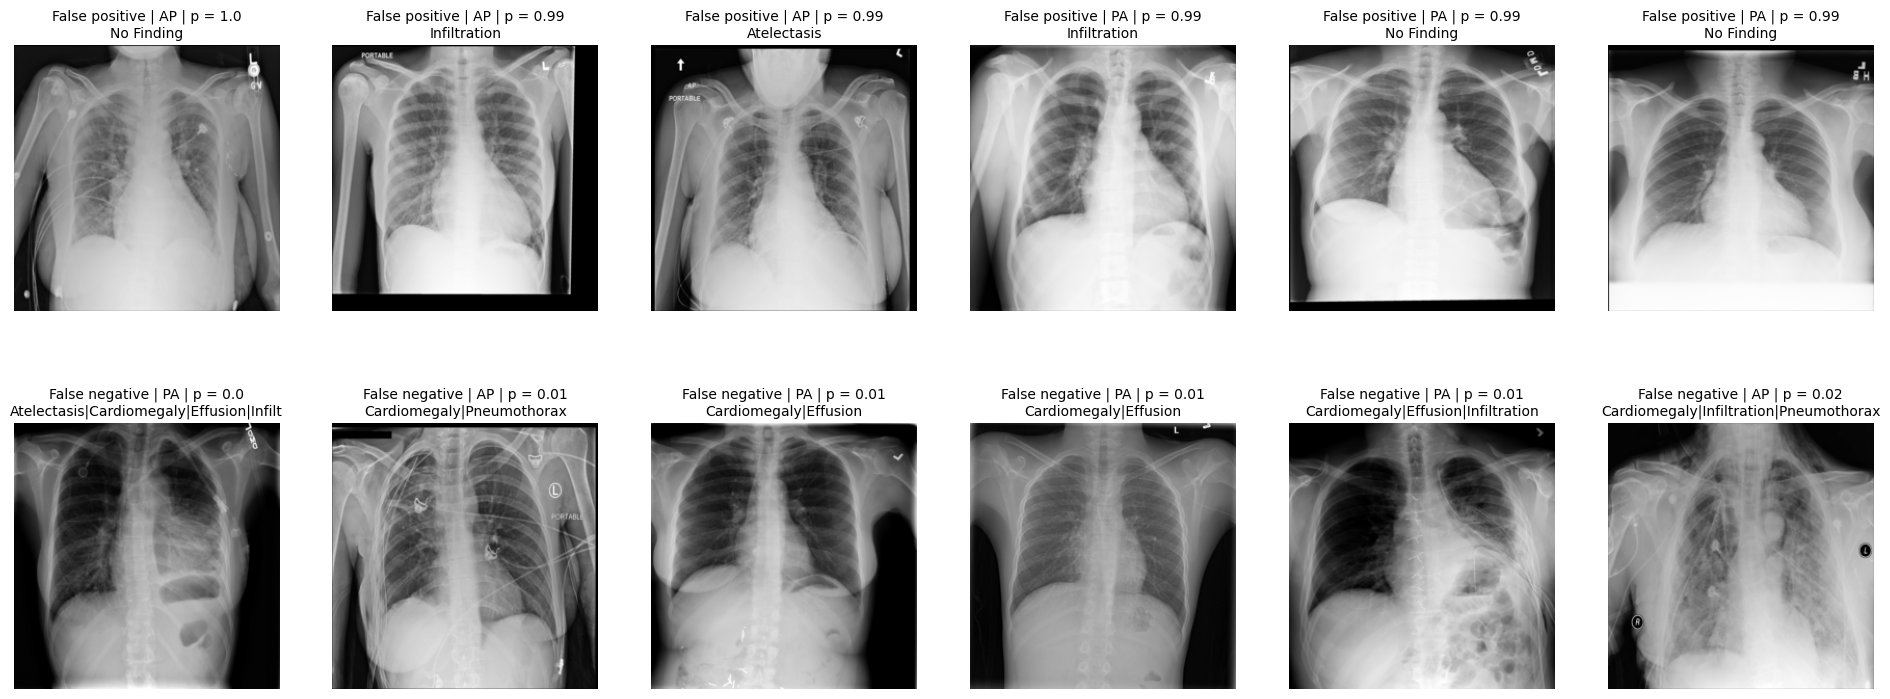

In [66]:
# the most confident mistakes
fp = test_df[(test_df['cardiomegaly'] == 0) & (test_df['pred'] == 1)].sort_values('prob', ascending = False).head(6)
fn = test_df[(test_df['cardiomegaly'] == 1) & (test_df['pred'] == 0)].sort_values('prob', ascending = True).head(6)

fig, axes = plt.subplots(nrows = 2, ncols = 6, figsize = (24, 9))
for row_axes, group, title in [(axes[0], fp, 'False positive'), (axes[1], fn, 'False negative')]:
    for ax, (_, r) in zip(row_axes, group.iterrows()):
        ax.imshow(Image.open(os.path.join(img_dir, r['image'])), cmap = 'gray')
        ax.set_title(title + ' | ' + r['view'] + ' | p = ' + str(round(r['prob'], 2)) + '\n' + r['findings'][:40], fontsize = 10)
        ax.axis('off')
plt.show()

# ---- Output of this cell (copied from the run) ----
# Figure, not text. 12 images, titles as printed:
# Top row, most confident false positives (true label has no cardiomegaly):
#   AP p=1.00 No Finding | AP p=0.99 Infiltration | AP p=0.99 Atelectasis |
#   PA p=0.99 Infiltration | PA p=0.99 No Finding | PA p=0.99 No Finding
# Bottom row, most confident false negatives (true label is cardiomegaly):
#   PA p=0.00 Atelectasis|Cardiomegaly|Effusion|Infilt.. | AP p=0.01 Cardiomegaly|Pneumothorax |
#   PA p=0.01 Cardiomegaly|Effusion | PA p=0.01 Cardiomegaly|Effusion |
#   PA p=0.01 Cardiomegaly|Effusion|Infiltration | AP p=0.02 Cardiomegaly|Infiltration|Pneumothorax

In [67]:
# what the mistakes have in common: view and other findings
for name, group in [('False negatives', test_df[(test_df['cardiomegaly'] == 1) & (test_df['pred'] == 0)]),
                    ('Detected cardiomegaly', test_df[(test_df['cardiomegaly'] == 1) & (test_df['pred'] == 1)])]:
    print(name, '| n =', len(group), '| AP share =', round((group['view'] == 'AP').mean(), 3))
    print(group['findings'].str.split('|').explode().value_counts().head(6).to_string())
    print()

# ---- Output of this cell (copied from the run) ----
# False negatives | n = 187 | AP share = 0.781
# findings
# Cardiomegaly          187
# Effusion              119
# Infiltration           57
# Atelectasis            36
# Consolidation          31
# Pleural_Thickening     18
#
# Detected cardiomegaly | n = 882 | AP share = 0.562
# findings
# Cardiomegaly     882
# Effusion         333
# Infiltration     247
# Atelectasis      142
# Consolidation     74
# Edema             57

False negatives | n = 187 | AP share = 0.781
findings
Cardiomegaly          187
Effusion              119
Infiltration           57
Atelectasis            36
Consolidation          31
Pleural_Thickening     18

Detected cardiomegaly | n = 882 | AP share = 0.562
findings
Cardiomegaly     882
Effusion         333
Infiltration     247
Atelectasis      142
Consolidation     74
Edema             57



**Result 5 - misses are mostly AP films with fluid, and the worst errors look like label problems**

The numbers (from the table above):

| | n | AP share | with effusion | with consolidation | with infiltration |
|---|---|---|---|---|---|
| missed cardiomegaly (false negatives) | 187 | **78%** | **64%** | **17%** | 31% |
| detected cardiomegaly | 882 | 56% | 38% | 8% | 28% |

- 187 of 1,069 positives are missed (17.5%). The AP miss rate is 23% (146 of 642) and the PA miss rate is 10% (41 of 427), the same as 1 - recall in section 1.
- Effusion is present in 64% of the misses and 38% of the detected cases, consolidation is twice as common in the misses. Infiltration and atelectasis are about the same in both groups. A plausible reason is that fluid and consolidation hide the heart border on the film, so the heart size can not be read. That is a pattern in the data, not proof of the cause.

What the picture shows (read this as a non-radiologist looking at the images):
- **The mistakes are extremely confident**: all six top false positives have p >= 0.99 and all six top false negatives have p <= 0.02. A model that sure and wrong is a signal to check the labels, not only the model.
- 3 of the 6 top false positives are labelled "No Finding", with a score of 0.99 or higher.
- 4 of the 6 most confident misses are **PA** films (not AP), labelled with cardiomegaly plus effusion or infiltration. In at least two of them (the third and fourth) the heart does not look clearly enlarged to me. If a radiologist agrees, those are label errors (NIH labels come from text mining of reports) and not model errors.
- Two of the six misses have pneumothorax listed and at least one shows lines or leads, so devices and post-procedure films may be another hard group (too few images here to say).

This can not be settled without a radiologist. Two ways to check: ask someone with training to review these 12 images, or test the model on VinDr-CXR, whose labels were made by radiologists.

A side effect: scores of 0.99 and 0.01 mean the output is not a calibrated probability (the app already says so). Consider showing "high / medium / low" and not a percentage.

## 6. Test-time augmentation

In [68]:
import torchvision.transforms.functional as TF

class CXRShiftDataset(torch.utils.data.Dataset):
    # the same center crop as eval_tf, moved by (dx, dy) pixels. No flips (the heart has to stay on the left)
    def __init__(self, df, dx, dy):
        self.names = df['image'].values
        self.labels = df['cardiomegaly'].values
        self.top = (img_size - crop_size) // 2 + dy
        self.left = (img_size - crop_size) // 2 + dx
        self.tf = transforms.Compose([transforms.Grayscale(num_output_channels = 3), transforms.ToTensor(), transforms.Normalize(mean, std)])

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = Image.open(os.path.join(img_dir, self.names[idx])).convert('L')
        img = TF.crop(img, self.top, self.left, crop_size, crop_size)
        return self.tf(img), torch.tensor(self.labels[idx], dtype = torch.float32)

def predict_probs(model, loader):
    model.eval()
    out = []
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            with torch.autocast(device_type = device.type, dtype = torch.float16, enabled = use_amp):
                logits = model(images).squeeze(1)
            out.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(out)

def tta_probs(df_, shifts = [(0, 0), (12, 0), (-12, 0), (0, 12), (0, -12)]):
    runs = []
    for dx, dy in shifts:
        loader = DataLoader(CXRShiftDataset(df_, dx, dy), batch_size = 64, shuffle = False, num_workers = num_workers)
        runs.append(predict_probs(cnn_model, loader))
    return np.mean(runs, axis = 0)

In [69]:
val_tta = tta_probs(val_df)
test_tta = tta_probs(test_df)

print('Validation AUC : single crop', round(roc_auc_score(val_df['cardiomegaly'], val_df['prob']), 4), '| TTA', round(roc_auc_score(val_df['cardiomegaly'], val_tta), 4))
print('Test AUC :       single crop', round(roc_auc_score(test_df['cardiomegaly'], test_df['prob']), 4), '| TTA', round(roc_auc_score(test_df['cardiomegaly'], test_tta), 4))

# ---- Output of this cell (copied from the run) ----
# Validation AUC : single crop 0.9264 | TTA 0.9314
# Test AUC :       single crop 0.8801 | TTA 0.8836

Validation AUC : single crop 0.9264 | TTA 0.9314
Test AUC :       single crop 0.8801 | TTA 0.8836


**Result 6 - TTA gives a tiny gain, not worth 5x the time**

| ROC AUC | single crop | 5 shifted crops (TTA) | gain |
|---|---|---|---|
| validation | 0.9264 | 0.9314 | +0.005 |
| test | 0.8801 | 0.8836 | +0.0035 |

The gain is the same direction on both sets but far inside the confidence interval of section 2 (the interval is 0.04 wide). TTA runs the model 5 times per image, so the CPU latency would go from 127 ms to roughly 0.6 s. Not used in the app.

For the pathology project it is different: flips and 90-degree rotations are valid for tissue, so TTA over 8 orientations is cheap and normally worth testing.

## Save the extra numbers

In [70]:
cxr_config['test_metrics_ci95'] = {k: [float(ci.loc[0.025, k]), float(ci.loc[0.975, k])] for k in ci.columns}
cxr_config['test_metrics_by_view'] = {v: {k: float(x) for k, x in row.items()} for v, row in view_table(test_df, threshold).iterrows()}
cxr_config['val_threshold_by_view'] = view_threshold   # not used by the app, kept for reference
cxr_config['tta_test_auc'] = float(roc_auc_score(test_df['cardiomegaly'], test_tta))
json.dump(cxr_config, open(save_dir + '/cxr_config.json', 'w'), indent = 2)
cxr_config['test_metrics_ci95']

# ---- Output of this cell (copied from the run) ----
# {'roc_auc': [0.858, 0.898],
#  'recall': [0.779, 0.862],
#  'false positive rate': [0.235, 0.284]}

{'roc_auc': [0.858, 0.898],
 'recall': [0.779, 0.862],
 'false positive rate': [0.235, 0.284]}

`cxr_config.json` now also holds the confidence intervals, the per-view results, the per-view validation thresholds (reference only) and the TTA AUC. The app reads only `threshold`, `mean`, `std`, `img_size`, `crop_size` and `test_metrics`, so it needs no change.

# Summary of Part 2

| | value |
|---|---|
| training images / val / test | 7,310 / 793 / 3,001 (patient-wise, official NIH test list) |
| best epoch | 3 of 5 (early stopping), val AUC 0.926 |
| **test ROC AUC** | **0.880 (95% CI 0.858 - 0.898)** |
| test AUC, PA / AP | 0.925 / 0.846 |
| threshold (chosen on validation for 90% recall) | 0.45 |
| test recall at 0.45 | 0.825 (95% CI 0.779 - 0.862), target 0.90 **not** reached |
| test recall, PA / AP | 0.904 / 0.773 |
| false positive rate, all / "No Finding" / other findings | 0.259 / 0.255 / 0.262 |
| precision: this test set (36%) / at 2.5% prevalence | 0.638 / 0.075 |
| CPU latency, mean / p95 | 127 ms / 153 ms |
| TTA (5 crops) test AUC | 0.8836 (not used) |

**What the results say**
1. A solid first model: the AUC is in the usual range for cardiomegaly on NIH, with only 7k training images and no tuning.
2. The model is clearly better on PA films than on AP films, which is expected (the heart is magnified on AP films). It does not use the view as a shortcut.
3. The recall target (0.90) was missed by 7.5 points. Recall fell 9 points from validation (0.92) to test (0.83): about a third of that is the different view mix in the test set, the rest is an optimistic validation set. Use a safety margin when picking the threshold.
4. At real prevalence the precision is below 10%, so it is a triage score and not a diagnosis.
5. The most confident errors point to label noise or to hidden heart borders, which limits any score measured against NIH labels. A radiologist-labelled set (VinDr-CXR) is the next check.


**How the app combines the two models.** There is no dataset where the same patients have both UCI measurements and an X-ray, so the weight of each model in a combined score can not be learnt. Averaging the two probabilities with a made-up weight would look precise but would not be validated. The app shows both results side by side and gives a three-level answer: **higher concern** if both models are above their thresholds, **moderate concern** if only one is, **low concern** if neither is. A plain "either model flags" rule was not used: each model is set to catch about 90% of sick patients, so each also flags many healthy ones, and with both models that rule would flag roughly half of healthy users.

A real fusion model would need paired data, for example MIMIC-IV (clinical data) + MIMIC-CXR (X-rays of the same patients) on PhysioNet, which needs a credentialed account and a short ethics course.

Notes for the interview:
- Patient-wise split, the NIH test list is by patient. A random split on images leaks the same heart into the test set.
- No horizontal flip, the heart is on the left (for pathology tiles flips are fine).
- Negatives include other findings, so the model can not just learn "abnormal X-ray". Check: the false positive rate is the same on "No Finding" and on other findings (0.255 vs 0.262).
- PA vs AP: AP magnifies the heart. AUC 0.925 on PA and 0.846 on AP, so results are reported per view.
- The threshold chosen on validation did not transfer (0.92 recall on validation, 0.83 on test): validation was small and optimistic, and the test set has more AP films. Fix: a safety margin in the target, or a larger validation set.
- At 2.5% prevalence the precision is about 7.5%, so it is a triage score.
- NIH labels come from NLP on reports, so they are noisy. The most confident mistakes look like label problems, which could be tested on VinDr-CXR (radiologist labels).